# NB01 - Praproses Dataset dengan Otsu dan Dominasi Warna

Notebook ini menyiapkan citra buah dengan segmentasi Otsu grayscale per citra dan hitungan dominasi kanal warna pada tingkat kelas. Semua kelas yang kanal dominannya merah atau hijau diproses tanpa kuota jumlah kelas per domain. Metode tidak menggunakan klasifikasi khusus warna cokelat.

1. Setup dan konfigurasi
2. Inventarisasi dataset mentah
3. Segmentasi Otsu dan audit dominasi warna per kelas
4. Deduplikasi pHash per kelas
5. Center crop, resize, dan pembuatan manifest
6. Verifikasi hasil praproses
7. Undersampling seimbang per kelas dan domain
8. Analisis ringkas dan ekspor


In [1]:
%pip install opencv-python-headless numpy pillow imagehash pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


## Tahap 1 - Setup dan Konfigurasi

In [2]:
from __future__ import annotations

import json
import sys
import time
from pathlib import Path

import cv2
import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

CORE_CANDIDATES = [Path.cwd() / "core", *[p / "core" for p in Path.cwd().parents]]
CORE_DIR = next((p for p in CORE_CANDIDATES if (p / "utils.py").exists()), None)
if CORE_DIR is None:
    raise FileNotFoundError("Folder core/utils.py tidak ditemukan")
if str(CORE_DIR) not in sys.path:
    sys.path.insert(0, str(CORE_DIR))
from utils import find_research_root, sha256_file, write_csv

RESEARCH_ROOT = find_research_root("datasets/raw/fruits")
RAW_DATASET_DIR = RESEARCH_ROOT / "datasets" / "raw" / "fruits"
OUTPUT_DIR = RESEARCH_ROOT / "notebooks" / "01" / "output" / "tanpa_filter_cokelat"
PROCESSED_DIR = RESEARCH_ROOT / "datasets" / "processed" / "tanpa_filter_cokelat"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

SUBSET = "train"
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}
PHASH_THRESHOLD = 4
OUTPUT_SIZE = 512
RANDOM_SEED = 42
COLOR_SAMPLES_PER_IMAGE = 1000
METHOD_VERSION = "dataset-preparation-5.2-otsu-color-dominance"

# Algorithm parameters: tune against a representative validation subset and
# report the final values. These are not coefficients from the cited equations.

ALL_RAW_CLASSES = sorted(
    directory.name for directory in RAW_DATASET_DIR.iterdir()
    if directory.is_dir() and directory.name != "000neg" and (directory / SUBSET).exists()
)


## Tahap 2 - Inventarisasi Seluruh Kelas Mentah

In [3]:
def list_images(directory: Path) -> list[Path]:
    return sorted(path for path in directory.rglob("*") if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS)

inventory_rows = []
for source_class in ALL_RAW_CLASSES:
    class_dir = RAW_DATASET_DIR / source_class / SUBSET
    paths = list_images(class_dir) if class_dir.exists() else []
    inventory_rows.append({"source_class": source_class, "subset": SUBSET, "raw_image_count": len(paths), "source_directory": str(class_dir)})

inventory = pd.DataFrame(inventory_rows)
if (inventory["raw_image_count"] == 0).any():
    missing = inventory.loc[inventory["raw_image_count"] == 0, "source_class"].tolist()
    raise RuntimeError(f"Kelas tanpa citra pada subset train: {missing}")

print(inventory.to_string(index=False))
print(f"Total kelas mentah: {len(inventory)}")
print(f"Total citra raw: {int(inventory['raw_image_count'].sum())}")


  source_class subset  raw_image_count                                                           source_directory
      001apple  train              418       C:\colorblind_simulation\research\datasets\raw\fruits\001apple\train
     002orange  train              432      C:\colorblind_simulation\research\datasets\raw\fruits\002orange\train
       003pear  train              268        C:\colorblind_simulation\research\datasets\raw\fruits\003pear\train
     004tomato  train              411      C:\colorblind_simulation\research\datasets\raw\fruits\004tomato\train
 005strawberry  train              450  C:\colorblind_simulation\research\datasets\raw\fruits\005strawberry\train
     006banana  train              394      C:\colorblind_simulation\research\datasets\raw\fruits\006banana\train
 007watermelon  train              239  C:\colorblind_simulation\research\datasets\raw\fruits\007watermelon\train
       008kiwi  train              311        C:\colorblind_simulation\research\datasets

## Tahap 3 - Segmentasi Otsu dan Dominasi Warna pada Tingkat Kelas

Setiap citra diproses dengan ambang Otsu grayscale untuk membentuk mask foreground. Polaritas mask dipilih dari sisi biner yang memuat piksel tengah citra. Ini merupakan asumsi pemrosesan untuk memilih sisi objek setelah Otsu, bukan persamaan tambahan dari artikel. Dari foreground, piksel dengan kanal merah dominan dan kanal hijau dominan dihitung menggunakan persamaan dalam artikel segmentasi tomat.

Otsu yang digunakan mengikuti *FruitVision*, Bagian 3.2.2, Persamaan (1), yang menentukan ambang dengan meminimalkan varians dalam kelas tertimbang:

\[
\sigma_o^2(t)=w_1(t)\sigma_1^2(t)+w_2(t)\sigma_2^2(t)
\]

Di sini, \(w_1(t)\) dan \(w_2(t)\) adalah probabilitas dua kelas yang dibagi oleh ambang \(t\). Ambang dihitung oleh OpenCV dari histogram grayscale setiap citra. [Hayat et al., *Open Agriculture* 9 (2024), 20220276](https://doi.org/10.1515/opag-2022-0276).

Dominasi kanal mengikuti Arellano Arzola et al., *AgriEngineering* 5(4) (2023), Bagian 2, Persamaan (1) dan (2). Untuk kanal hijau:

\[
h(x,y)=\begin{cases}f(x,y), & f_G(x,y)\ge f_R(x,y)\;\text{dan}\;f_G(x,y)\ge f_B(x,y)\\0, & \text{lainnya}\end{cases}
\]

Untuk kanal merah:

\[
j(x,y)=\begin{cases}f(x,y), & f_R(x,y)\ge f_G(x,y)\;\text{dan}\;f_R(x,y)\ge f_B(x,y)\\0, & \text{lainnya}\end{cases}
\]

Persamaan (1) artikel memilih kanal hijau yang dominan terhadap merah dan biru, sedangkan Persamaan (2) memilih kanal merah yang dominan terhadap hijau dan biru. [Artikel dan persamaan](https://doi.org/10.3390/agriengineering5040113).

Penggabungan mask Otsu dan persamaan dominasi merupakan integrasi untuk alur NB01, bukan metode gabungan yang diklaim berasal dari salah satu artikel. Pengelompokan kelas pada notebook menggunakan hitungan piksel dominan merah dan hijau dari sampel foreground semua citra dalam kelas; keputusan berdasarkan hitungan lebih besar adalah aturan operasional notebook, bukan persamaan dari artikel. Kanal dengan hitungan lebih besar menjadi domain kelas; hitungan yang sama atau tidak adanya sampel dominan ditandai ambigu. Tidak ada batas hue, ambang rasio, margin dominasi, K-means, atau kuota kelas per domain.

**Batas penerapan literatur:** penelitian dominasi kanal menguji tanaman tomat di rumah kaca, dengan kanal hijau untuk daun dan merah untuk buah. Karena itu persamaan kanal hijau tidak membuktikan bahwa suatu kelas adalah buah hijau. Otsu dan dominasi kanal juga tidak mengenali kategori semantik seperti kiwi atau cokelat. Hasil ini harus diperlakukan sebagai audit otomatis berbasis piksel, bukan jaminan bahwa semua kelas tidak relevan telah ditolak.


In [4]:
def list_images(directory: Path) -> list[Path]:
    return sorted(
        path for path in directory.rglob("*")
        if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS
    )


def otsu_foreground_mask(image_bgr: np.ndarray) -> tuple[np.ndarray, float]:
    """Apply grayscale Otsu thresholding and choose the polarity containing the center pixel."""
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    threshold, binary_mask = cv2.threshold(
        gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    center_y, center_x = gray.shape[0] // 2, gray.shape[1] // 2
    foreground_mask = binary_mask if binary_mask[center_y, center_x] else cv2.bitwise_not(binary_mask)
    return foreground_mask > 0, float(threshold)


def sample_dominant_color_pixels(image_paths: list[Path]) -> tuple[int, int, int, int, int]:
    """Count red- and green-dominant sampled foreground pixels for one fruit class."""
    red_dominant_count = 0
    green_dominant_count = 0
    sampled_count = 0
    usable_images = 0
    otsu_thresholds = []
    rng = np.random.default_rng(RANDOM_SEED)

    for image_path in image_paths:
        image_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        if image_bgr is None:
            continue
        foreground_mask, otsu_threshold = otsu_foreground_mask(image_bgr)
        foreground_pixels = image_bgr[foreground_mask]
        if foreground_pixels.size == 0:
            continue

        sample_size = min(COLOR_SAMPLES_PER_IMAGE, len(foreground_pixels))
        sample_indices = rng.choice(len(foreground_pixels), size=sample_size, replace=False)
        sampled_bgr = foreground_pixels[sample_indices]
        blue = sampled_bgr[:, 0]
        green = sampled_bgr[:, 1]
        red = sampled_bgr[:, 2]

        # Color dominance equations from Arellano Arzola et al. (2023),
        # AgriEngineering 5(4), Section 2, Equations (1) and (2).
        # Equation (1): green channel >= red and blue (green foliage in that study).
        # Equation (2): red channel >= green and blue (tomato fruit in that study).
        green_dominant_count += int(np.count_nonzero((green >= red) & (green >= blue)))
        red_dominant_count += int(np.count_nonzero((red >= green) & (red >= blue)))
        sampled_count += int(sample_size)
        usable_images += 1
        otsu_thresholds.append(otsu_threshold)

    mean_otsu_threshold = float(np.mean(otsu_thresholds)) if otsu_thresholds else float("nan")
    return red_dominant_count, green_dominant_count, sampled_count, usable_images, mean_otsu_threshold


class_color_records = []
class_image_paths: dict[str, list[Path]] = {}
for class_name in ALL_RAW_CLASSES:
    paths = list_images(RAW_DATASET_DIR / class_name / SUBSET)
    class_image_paths[class_name] = paths
    red_count, green_count, sampled_count, usable_count, mean_threshold = sample_dominant_color_pixels(paths)
    if red_count > green_count:
        domain = "Red-Orange"
        status = "Selected"
        rejection_reason = ""
    elif green_count > red_count:
        domain = "Green-Yellow"
        status = "Selected"
        rejection_reason = ""
    else:
        domain = "Ambiguous"
        status = "Rejected"
        rejection_reason = "no_dominant_channel_or_tie"
    class_color_records.append({
        "source_class": class_name,
        "image_count": len(paths),
        "usable_image_count": usable_count,
        "sampled_pixel_count": sampled_count,
        "mean_otsu_threshold_gray": mean_threshold,
        "red_dominant_pixel_count": red_count,
        "green_dominant_pixel_count": green_count,
        "domain": domain,
        "status": status,
        "rejection_reason": rejection_reason,
    })

color_audit = pd.DataFrame(class_color_records)
red_selected = color_audit.loc[color_audit["domain"] == "Red-Orange", "source_class"].tolist()
green_selected = color_audit.loc[color_audit["domain"] == "Green-Yellow", "source_class"].tolist()
SELECTED_CLASSES = tuple(sorted(red_selected + green_selected))
if not red_selected or not green_selected:
    raise RuntimeError(
        "Otsu dan dominasi kanal belum menghasilkan kelas pada kedua kelompok. "
        "Periksa mask foreground dan hasil audit warna."
    )
valid_domain_by_class = {
    **{name: "Red-Orange" for name in red_selected},
    **{name: "Green-Yellow" for name in green_selected},
}
eliminated_classes = color_audit.loc[color_audit["status"] != "Selected", "source_class"].tolist()
valid_images_by_class = {
    class_name: class_image_paths[class_name]
    for class_name in SELECTED_CLASSES
}

print("Kelas dengan dominasi kanal merah:", red_selected)
print("Kelas dengan dominasi kanal hijau:", green_selected)
print(color_audit.sort_values(["domain", "source_class"]).to_string(index=False))
print(f"Total citra pada kelas terpilih sebelum deduplikasi: {sum(map(len, valid_images_by_class.values()))}")


Kelas dengan dominasi kanal merah: ['001apple', '002orange', '003pear', '004tomato', '005strawberry', '006banana', '008kiwi', '009peach', '010pomegranate', '011pineapple', '012starfruit', '013grape', '014lemon', '015pomelo', '016mango', '017durian', '019papaya']
Kelas dengan dominasi kanal hijau: ['007watermelon', '018hami']
  source_class  image_count  usable_image_count  sampled_pixel_count  mean_otsu_threshold_gray  red_dominant_pixel_count  green_dominant_pixel_count       domain   status rejection_reason
 007watermelon          239                 239               239000                143.903766                     18301                      211040 Green-Yellow Selected                 
       018hami          102                 102               102000                153.764706                     51355                       52581 Green-Yellow Selected                 
      001apple          418                 418               418000                157.617225               

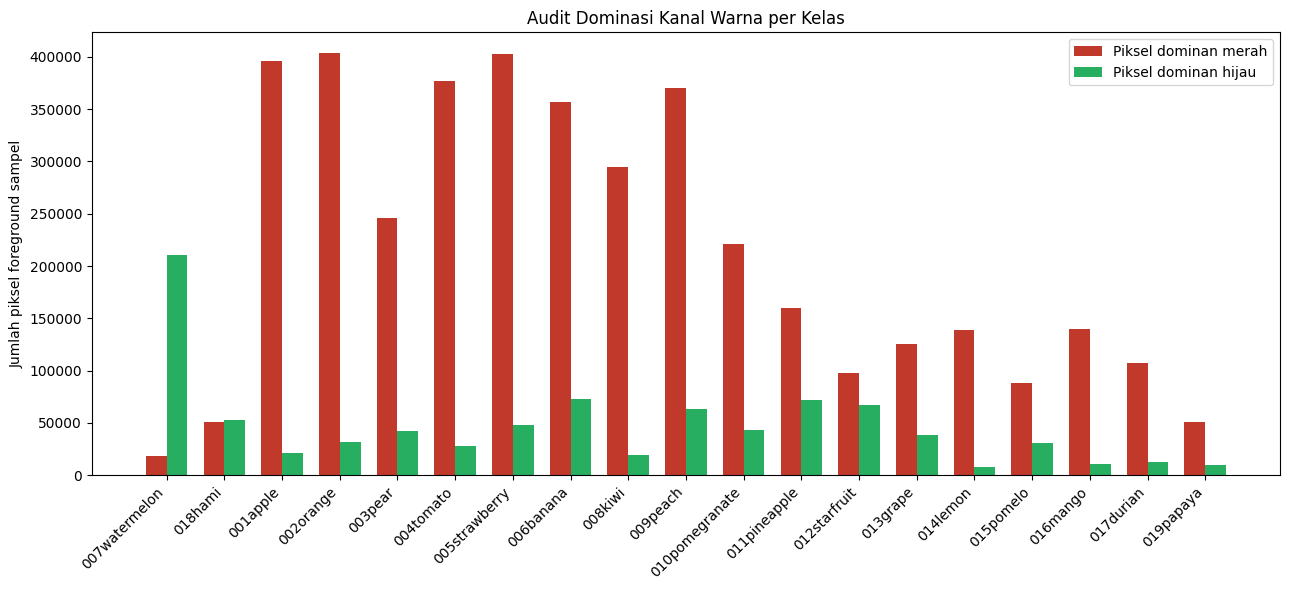

In [5]:
fig, ax = plt.subplots(figsize=(13, 6))
audit_plot = color_audit.sort_values(["domain", "source_class"])
x = np.arange(len(audit_plot))
width = 0.36
ax.bar(x - width / 2, audit_plot["red_dominant_pixel_count"], width, label="Piksel dominan merah", color="#c0392b")
ax.bar(x + width / 2, audit_plot["green_dominant_pixel_count"], width, label="Piksel dominan hijau", color="#27ae60")
ax.set_xticks(x)
ax.set_xticklabels(audit_plot["source_class"], rotation=45, ha="right")
ax.set_ylabel("Jumlah piksel foreground sampel")
ax.set_title("Audit Dominasi Kanal Warna per Kelas")
ax.legend()
plt.tight_layout()
plt.show()


### Audit Otsu dan Dominasi Warna

Grafik memperlihatkan jumlah piksel sampel foreground yang memenuhi dominasi kanal merah atau hijau pada setiap kelas. Ambang grayscale Otsu dihitung per citra, lalu kelas dikelompokkan berdasarkan kanal dominan yang memiliki hitungan lebih besar. Tidak ada ambang hue, rasio kelolosan, margin, K-means, atau pemilihan jumlah kelas tetap.


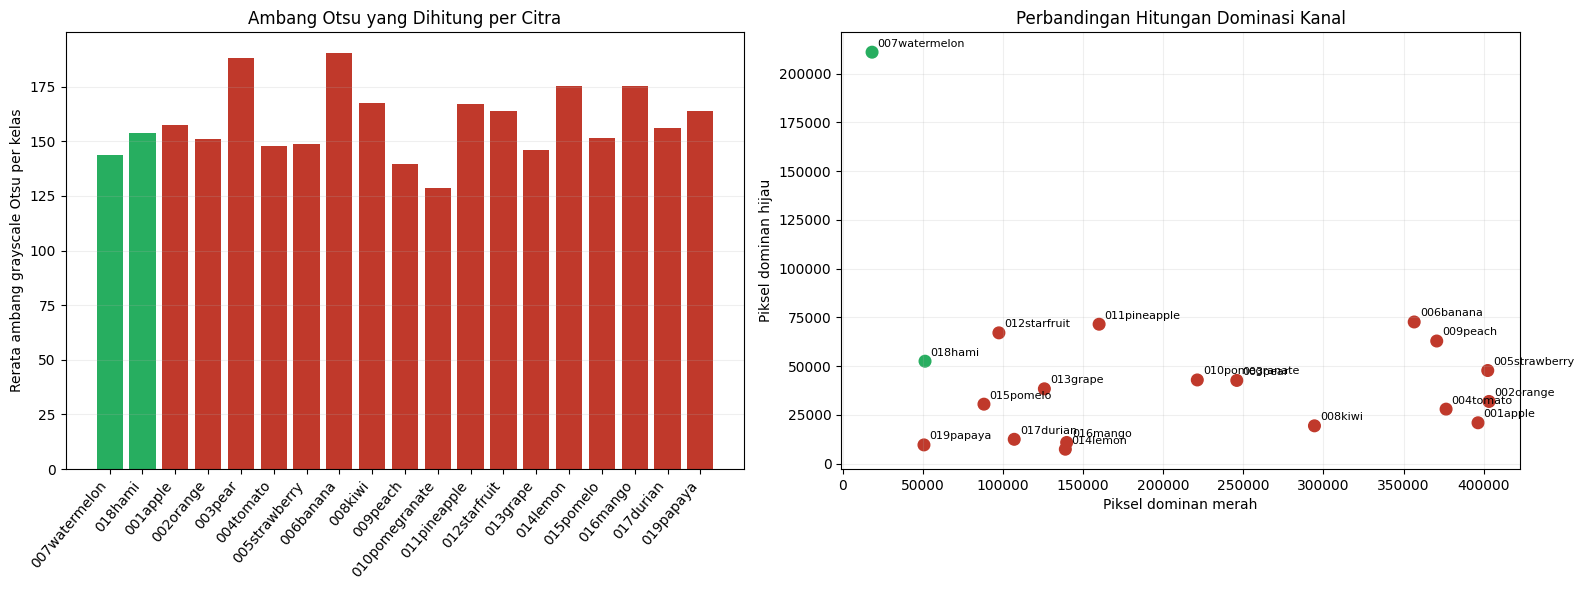

Grafik analisis seleksi kelas disimpan: C:\colorblind_simulation\research\notebooks\01\output\tanpa_filter_cokelat\class_selection_analysis.png


In [6]:
# Visualisasi ambang Otsu per citra yang diringkas pada tingkat kelas dan dominasi kanal.
plot_data = color_audit.sort_values(["domain", "source_class"]).reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
positions = np.arange(len(plot_data))
colors = ["#c0392b" if domain == "Red-Orange" else "#27ae60" if domain == "Green-Yellow" else "#7f8c8d" for domain in plot_data["domain"]]
axes[0].bar(positions, plot_data["mean_otsu_threshold_gray"], color=colors)
axes[0].set_xticks(positions)
axes[0].set_xticklabels(plot_data["source_class"], rotation=50, ha="right")
axes[0].set_ylabel("Rerata ambang grayscale Otsu per kelas")
axes[0].set_title("Ambang Otsu yang Dihitung per Citra")
axes[0].grid(axis="y", alpha=0.2)

axes[1].scatter(
    plot_data["red_dominant_pixel_count"],
    plot_data["green_dominant_pixel_count"],
    c=colors,
    s=70,
)
for _, row in plot_data.iterrows():
    axes[1].annotate(
        row["source_class"],
        (row["red_dominant_pixel_count"], row["green_dominant_pixel_count"]),
        xytext=(4, 4), textcoords="offset points", fontsize=8,
    )
axes[1].set_xlabel("Piksel dominan merah")
axes[1].set_ylabel("Piksel dominan hijau")
axes[1].set_title("Perbandingan Hitungan Dominasi Kanal")
axes[1].grid(alpha=0.2)
fig.tight_layout()
analysis_chart_path = OUTPUT_DIR / "class_selection_analysis.png"
fig.savefig(analysis_chart_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Grafik analisis seleksi kelas disimpan: {analysis_chart_path}")


## Tahap 4 - Deduplikasi Perceptual Hash (pHash) Intra-Kelas

Deduplikasi dilakukan dalam kelas yang sama menggunakan *perceptual hash* berbasis Discrete Cosine Transform (DCT-II 2D $32 \times 32$) dan kuantisasi median koefisien frekuensi rendah $8 \times 8$ (*Mahmud, Nusrat, & Pan, 2026, Eq. 3-6; Zauner, 2010*).

Dua citra dalam kelas yang sama diklasifikasikan sebagai duplikat visual jika jarak Hamming antar-hash biner 64-bit tidak melebihi ambang batas 4 ($d_H \le 4$).

In [7]:
# -- Deduplikasi Perceptual Hash (pHash) Intra-Kelas --
# Referensi Ilmiah Terverifikasi:
#   Mahmud, M. F., Nusrat, Z., & Pan, W. D. (2026). Electronics, 15(7), 1493.
#   Equations (3)-(6): 2D DCT-II, Median 8x8 Quantization, and Hamming Distance.

def compute_phash(image_path: Path) -> imagehash.ImageHash:
    with Image.open(image_path) as img:
        return imagehash.phash(img)


def deduplicate_images(
    image_paths: list[Path],
    threshold: int = PHASH_THRESHOLD,
) -> tuple[list[Path], list[tuple[Path, Path, int]]]:
    kept: list[Path] = []
    kept_hashes: list[imagehash.ImageHash] = []
    duplicates: list[tuple[Path, Path, int]] = []

    for path in image_paths:
        img_hash = compute_phash(path)
        is_duplicate = False
        for existing_hash, existing_path in zip(kept_hashes, kept):
            distance = img_hash - existing_hash
            if distance <= threshold:
                duplicates.append((path, existing_path, distance))
                is_duplicate = True
                break
        if not is_duplicate:
            kept.append(path)
            kept_hashes.append(img_hash)
    return kept, duplicates


dedup_results: dict[str, list[Path]] = {}
duplicate_records: list[dict] = []

# Hanya memproses citra yang lolos seleksi kemurnian kromatis dari 12 kelas terpilih
for cls_name in SELECTED_CLASSES:
    class_images = valid_images_by_class[cls_name]
    kept, dups = deduplicate_images(class_images, threshold=PHASH_THRESHOLD)
    dedup_results[cls_name] = kept
    for dup_path, orig_path, dist in dups:
        duplicate_records.append({
            "class": cls_name,
            "duplicate_file": dup_path.name,
            "kept_file": orig_path.name,
            "hamming_distance": dist,
        })

dedup_df = pd.DataFrame(duplicate_records)
print(f"Total kelas terpilih      : {len(SELECTED_CLASSES)}")
print(f"Total citra murni terpilih : {sum(len(v) for v in valid_images_by_class.values())}")
print(f"Total duplikat disaring   : {len(duplicate_records)}")
print(f"Total citra unik dipertahankan : {sum(len(v) for v in dedup_results.values())}")

# Bentuk daftar kandidat untuk praproses
candidates = [(cls_name, path) for cls_name in SELECTED_CLASSES for path in dedup_results[cls_name]]
print(f"Total kandidat unik siap praproses: {len(candidates)}")


Total kelas terpilih      : 19
Total citra murni terpilih : 4870
Total duplikat disaring   : 178
Total citra unik dipertahankan : 4692
Total kandidat unik siap praproses: 4692


## Tahap 5 - Normalisasi Geometris (Center Crop & Resize)

Citra dipotong secara simetris di bagian tengah (titik potong $(W - W_c)/2$ dan $(H - H_c)/2$) untuk menjaga rasio aspek objek 1:1 tanpa distorsi, kemudian di-resize ke resolusi seragam $512 \times 512$ piksel menggunakan interpolasi area (*Xiao et al., 2025, Eq. 4*).

In [8]:
# -- Normalisasi Geometris: Center-Crop Resizing 512x512 --
# Referensi Ilmiah Terverifikasi:
#   Xiao, Y. et al. (2025). J. Mar. Sci. Eng., 13(5), 936. (Equation 4: Center-Crop Transformation Matrix)

def center_crop_resize(source_path: Path, destination_path: Path, size: int) -> None:
    image = cv2.imread(str(source_path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError("Citra tidak dapat dibaca oleh OpenCV")
    height, width = image.shape[:2]
    edge = min(height, width)
    top, left = (height - edge) // 2, (width - edge) // 2
    cropped = image[top:top + edge, left:left + edge]
    resized = cv2.resize(cropped, (size, size), interpolation=cv2.INTER_AREA)
    destination_path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(destination_path), resized):
        raise IOError("Citra hasil tidak dapat ditulis")

manifest_rows: list[dict] = []
error_rows: list[dict] = []
for source_class, source_path in candidates:
    output_path = PROCESSED_DIR / source_class / f"{source_path.stem}.png"
    try:
        started = time.perf_counter()
        center_crop_resize(source_path, output_path, OUTPUT_SIZE)
        manifest_rows.append({"subset": SUBSET, "source_class": source_class, "source_file_name": source_path.name, "source_path": str(source_path), "output_file_name": output_path.name, "output_path": str(output_path), "output_sha256": sha256_file(output_path), "processing_seconds": round(time.perf_counter() - started, 6), "method_version": METHOD_VERSION})
    except Exception as error:
        error_rows.append({"stage": "preprocessing", "source_class": source_class, "source_path": str(source_path), "error": str(error)})

manifest = pd.DataFrame(manifest_rows).sort_values(["source_class", "source_file_name"]).reset_index(drop=True)
manifest["color_domain"] = manifest["source_class"].map(valid_domain_by_class)
if manifest.empty:
    raise RuntimeError("Tidak ada citra yang berhasil diproses.")
print(f"Citra berhasil diproses: {len(manifest)}")


Citra berhasil diproses: 4692


## Tahap 6 - Verifikasi Hasil Praproses

In [9]:
verification_rows = []
for _, row in manifest.iterrows():
    image = cv2.imread(row["output_path"], cv2.IMREAD_COLOR)
    verification_rows.append({"source_class": row["source_class"], "output_path": row["output_path"], "readable": image is not None, "width": None if image is None else int(image.shape[1]), "height": None if image is None else int(image.shape[0])})
verification = pd.DataFrame(verification_rows)
if not verification["readable"].all() or not ((verification["width"] == OUTPUT_SIZE) & (verification["height"] == OUTPUT_SIZE)).all():
    raise RuntimeError("Verifikasi ukuran atau keterbacaan citra gagal.")
print(f"Seluruh {len(verification)} citra berukuran {OUTPUT_SIZE} × {OUTPUT_SIZE} piksel.")

Seluruh 4692 citra berukuran 512 × 512 piksel.


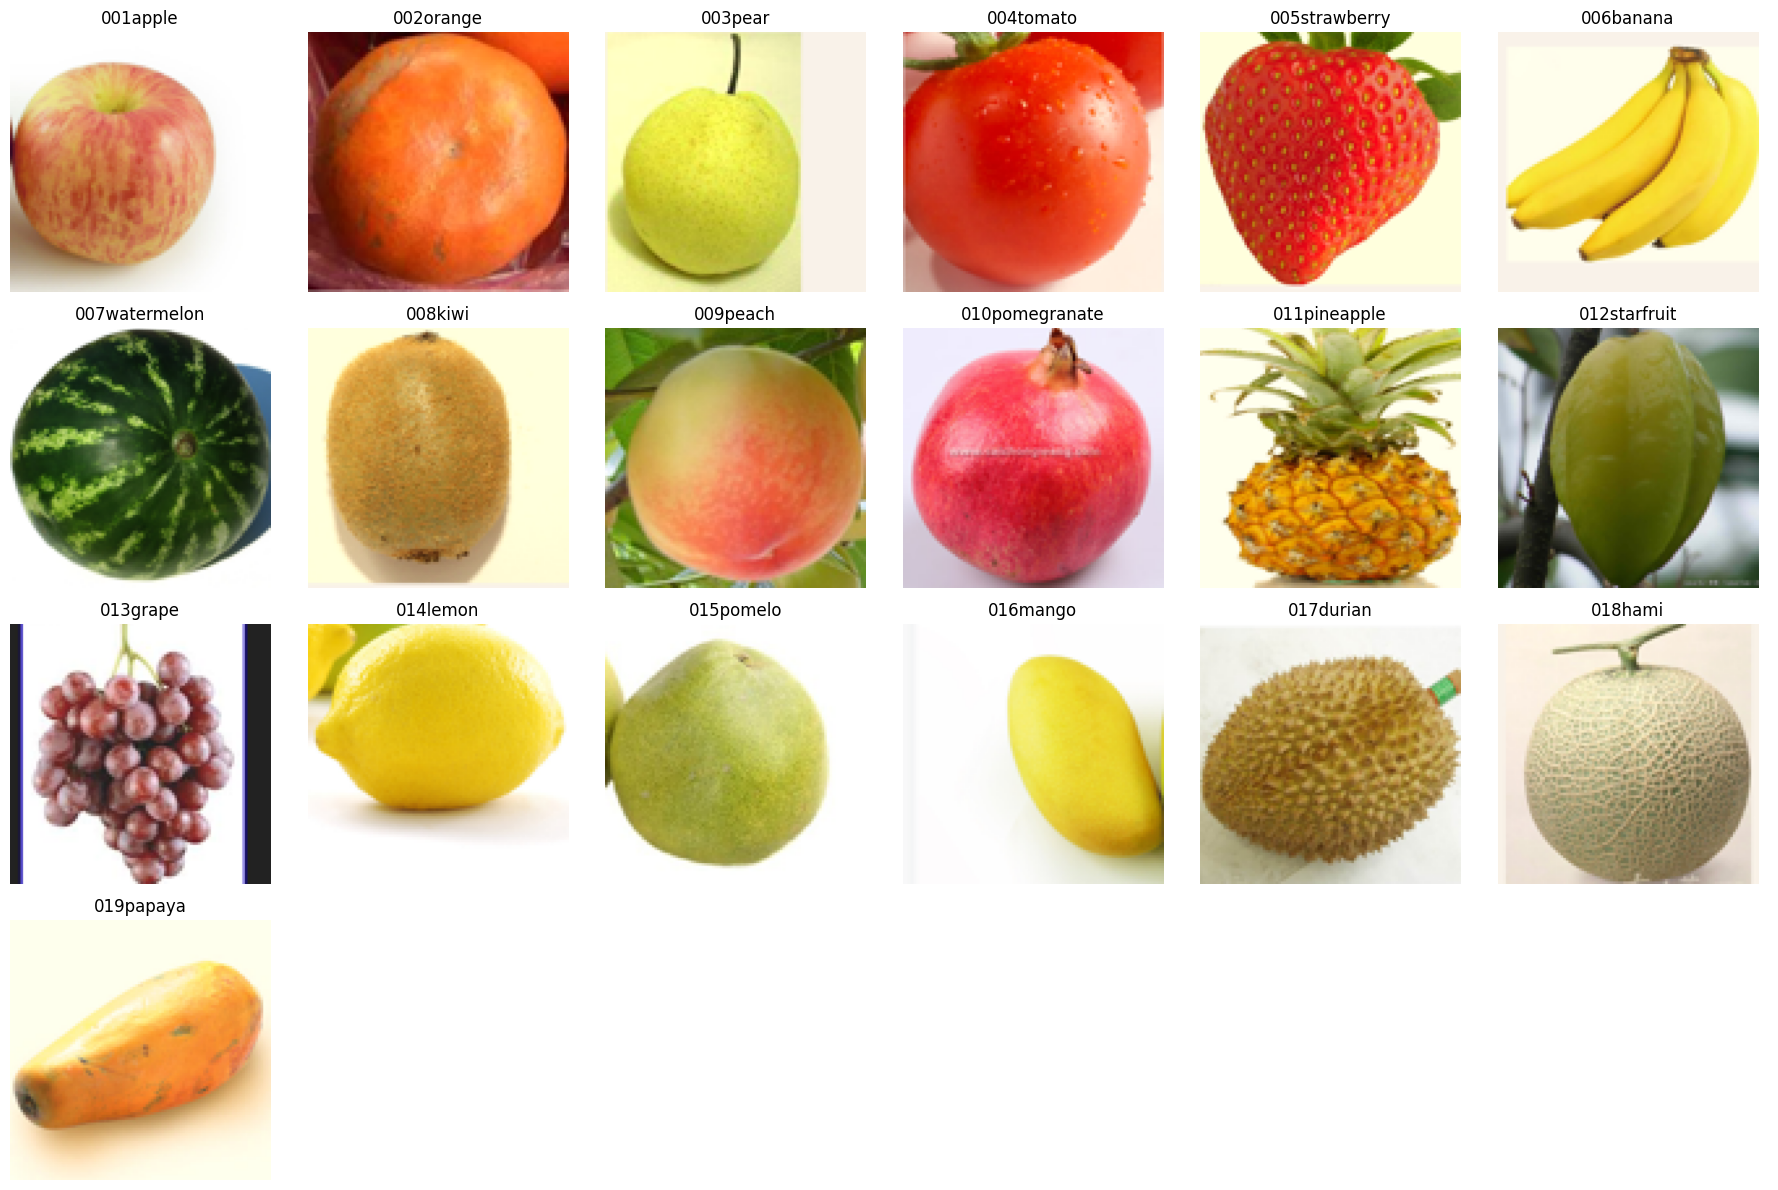

In [10]:
import math

# Mengambil 1 sampel acak untuk setiap kelas dari dataframe manifest
if "manifest" not in globals():
    raise RuntimeError(
        "Variabel `manifest` belum tersedia. Jalankan sel Tahap 4 terlebih dahulu."
    )

sample_df = (
    manifest.groupby("source_class")
    .sample(n=1, random_state=42)
    .reset_index(drop=True)
)

# Hitung jumlah baris & kolom secara dinamis
num_samples = len(sample_df)
ncols = 6
nrows = math.ceil(num_samples / ncols)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(3 * ncols, 3 * nrows))
axes = axes.flatten()

for idx, row in sample_df.iterrows():
    img = cv2.imread(row['output_path'])
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    axes[idx].imshow(img_rgb)
    axes[idx].set_title(row['source_class'], fontsize=12)
    axes[idx].axis('off')

# Matikan sisa subplot kosong jika total slot melebihi jumlah data
for j in range(num_samples, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

## Tahap 7 - Undersampling Seimbang per Kelas dan Domain

Kuota per kelas ditentukan berdasarkan kelas terpilih dengan citra valid paling sedikit. Setiap kelas mengambil jumlah citra tersebut dengan sampling acak ber-seed tetap. Setelah sampling per kelas, notebook menyeimbangkan jumlah citra total per domain. Akibatnya, jumlah citra per kelas dalam hasil akhir dapat berbeda. Ini merupakan keputusan desain sampling, bukan persamaan Otsu atau dominasi kanal. Distribusi sebelum dan sesudah sampling diekspor agar keputusan dapat diaudit.


In [11]:
# Undersampling deterministik: seluruh kelas lolos dipertahankan, lalu total domain diseimbangkan.
class_counts_before = manifest.groupby("source_class").size()
domain_counts_before = manifest.groupby("color_domain").size()
class_quota = int(class_counts_before.loc[list(SELECTED_CLASSES)].min())
if class_quota <= 0:
    raise RuntimeError("Kuota undersampling per kelas harus lebih dari nol.")

class_chunks = []
for class_name in SELECTED_CLASSES:
    class_rows = manifest[manifest["source_class"] == class_name]
    class_chunks.append(class_rows.sample(n=class_quota, random_state=RANDOM_SEED))
manifest_class_balanced = pd.concat(class_chunks, ignore_index=True)
class_counts_after_class_balance = manifest_class_balanced.groupby("source_class").size()
domain_class_balanced_counts = manifest_class_balanced.groupby("color_domain").size()
if set(domain_class_balanced_counts.index) != {"Red-Orange", "Green-Yellow"}:
    raise RuntimeError(f"Domain hasil sampling tidak lengkap: {domain_class_balanced_counts.to_dict()}")

# Ambil jumlah citra sama dari kedua domain; kelas terbanyak tidak dibatasi.
domain_quota = int(domain_class_balanced_counts.min())
domain_chunks = []
for domain_name in ("Red-Orange", "Green-Yellow"):
    domain_rows = manifest_class_balanced[manifest_class_balanced["color_domain"] == domain_name]
    domain_chunks.append(domain_rows.sample(n=domain_quota, random_state=RANDOM_SEED))
manifest_balanced = (
    pd.concat(domain_chunks, ignore_index=True)
    .sort_values(["color_domain", "source_class", "source_file_name"])
    .reset_index(drop=True)
)
class_counts_after = manifest_balanced.groupby("source_class").size()
domain_counts_after = manifest_balanced.groupby("color_domain").size()
if not (domain_counts_after == domain_quota).all():
    raise RuntimeError(f"Jumlah domain tidak seimbang: {domain_counts_after.to_dict()}")
print(f"Kuota awal per kelas: {class_quota}")
print(f"Kuota citra akhir per domain: {domain_quota}")
print("Distribusi kelas setelah undersampling domain:")
print(class_counts_after.to_string())
print("Distribusi domain setelah undersampling:")
print(domain_counts_after.to_string())
print(f"Total citra setelah undersampling: {len(manifest_balanced)}")

manifest_original = manifest.copy()
manifest = manifest_balanced


Kuota awal per kelas: 58
Kuota citra akhir per domain: 116
Distribusi kelas setelah undersampling domain:
source_class
001apple           4
002orange         10
003pear            5
004tomato          4
005strawberry      9
006banana          8
007watermelon     58
008kiwi            6
009peach           6
010pomegranate     7
011pineapple       7
012starfruit       8
013grape           8
014lemon           6
015pomelo          7
016mango           7
017durian          7
018hami           58
019papaya          7
Distribusi domain setelah undersampling:
color_domain
Green-Yellow    116
Red-Orange      116
Total citra setelah undersampling: 232


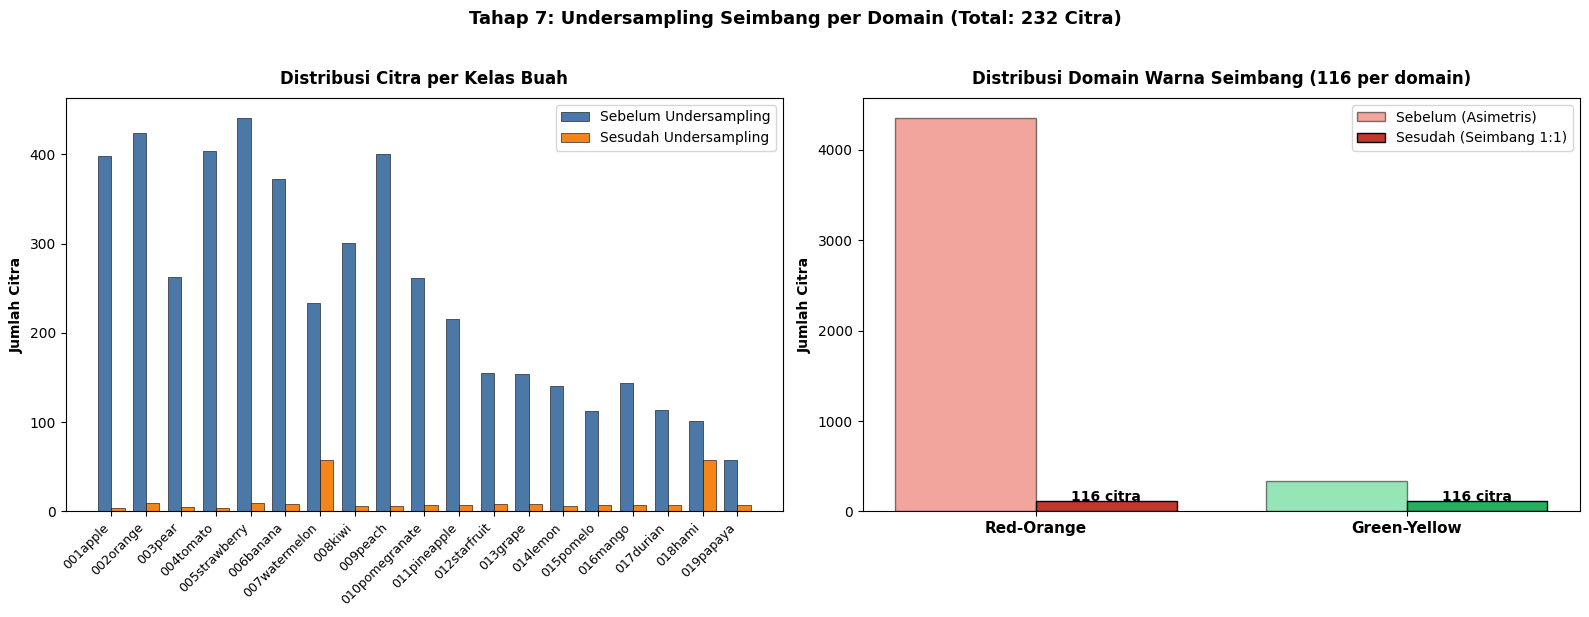

Laporan undersampling disimpan: C:\colorblind_simulation\research\notebooks\01\output\tanpa_filter_cokelat\undersampling_report.csv


In [12]:
# -- Visualisasi Perbandingan Sebelum vs Sesudah Undersampling Domain --
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel kiri: per-kelas buah
cls_names = sorted(list(SELECTED_CLASSES))
before_vals = [int(class_counts_before.get(c, 0)) for c in cls_names]
after_vals = [int(class_counts_after.get(c, 0)) for c in cls_names]
x = np.arange(len(cls_names))
width = 0.38

axes[0].bar(x - width/2, before_vals, width, label="Sebelum Undersampling", color="#4C78A8", edgecolor="black", linewidth=0.4)
axes[0].bar(x + width/2, after_vals, width, label="Sesudah Undersampling", color="#F58518", edgecolor="black", linewidth=0.4)
axes[0].set_xticks(x)
axes[0].set_xticklabels(cls_names, rotation=45, ha="right", fontsize=9)
axes[0].set_ylabel("Jumlah Citra", fontweight="bold")
axes[0].set_title("Distribusi Citra per Kelas Buah", fontweight="bold", pad=10)
axes[0].legend(frameon=True, facecolor="white")

# Panel kanan: per domain warna
domain_names = ["Red-Orange", "Green-Yellow"]
domain_before_vals = [int(domain_counts_before["Red-Orange"]), int(domain_counts_before["Green-Yellow"])]
domain_after_vals = [int(domain_counts_after["Red-Orange"]), int(domain_counts_after["Green-Yellow"])]
xd = np.arange(len(domain_names))

axes[1].bar(xd - width/2, domain_before_vals, width, label="Sebelum (Asimetris)", color=["#e74c3c", "#2ecc71"], alpha=0.5, edgecolor="black")
axes[1].bar(xd + width/2, domain_after_vals, width, label="Sesudah (Seimbang 1:1)", color=["#c0392b", "#27ae60"], edgecolor="black")
axes[1].set_xticks(xd)
axes[1].set_xticklabels(domain_names, fontsize=11, fontweight="bold")
axes[1].set_ylabel("Jumlah Citra", fontweight="bold")
axes[1].set_title(f"Distribusi Domain Warna Seimbang ({domain_quota} per domain)", fontweight="bold", pad=10)
axes[1].legend(frameon=True, facecolor="white")

for i, val in enumerate(domain_after_vals):
    axes[1].text(i + width/2, val + max(1, domain_quota * 0.02), f"{val} citra", ha="center", fontweight="bold")

plt.suptitle(
    f"Tahap 7: Undersampling Seimbang per Domain (Total: {len(manifest)} Citra)",
    fontsize=13, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "undersampling_chart.png", dpi=180, bbox_inches="tight")
plt.show()

# Simpan laporan undersampling
undersample_report = pd.DataFrame({
    "source_class": cls_names,
    "domain": [valid_domain_by_class[c] for c in cls_names],
    "before_count": before_vals,
    "after_count": after_vals,
    "removed": [b - a for b, a in zip(before_vals, after_vals)],
    "class_quota_awal": [class_quota] * len(cls_names),
    "after_count_domain_balancing": [int(class_counts_after.get(c, 0)) for c in cls_names],
})
write_csv(undersample_report, OUTPUT_DIR / "undersampling_report.csv", ["source_class"])
print(f"Laporan undersampling disimpan: {OUTPUT_DIR / 'undersampling_report.csv'}")


## Tahap 8 - Analisis Ringkas dan Ekspor

In [13]:
# -- Tahap 8: Ekspor Seluruh Laporan dan Manifest Praproses --
import shutil

class_counts = manifest.groupby("source_class").size().rename("processed_count")
domain_counts = manifest.groupby("color_domain").size().rename("domain_count")

# 1. Simpan Manifest Utama untuk NB02 (dataset_preparation_report.csv & manifest.csv)
report_path = OUTPUT_DIR / "dataset_preparation_report.csv"
write_csv(manifest, report_path, ["source_class", "source_file_name"])
manifest_csv_path = OUTPUT_DIR / "manifest.csv"
manifest.to_csv(manifest_csv_path, index=False)
print(f"[1/6] Manifest utama NB02 disimpan: {report_path}")

# 2. Simpan Laporan Error Praproses (dataset_preparation_errors.csv & dataset_preparation_error.csv)
error_cols = ["stage", "source_class", "source_path", "error"]
errors_df = pd.DataFrame(error_rows, columns=error_cols) if error_rows else pd.DataFrame(columns=error_cols)
write_csv(errors_df, OUTPUT_DIR / "dataset_preparation_errors.csv", ["stage", "source_class", "source_path"], allow_empty=True)
errors_df.to_csv(OUTPUT_DIR / "dataset_preparation_error.csv", index=False)
print(f"[2/6] Laporan error praproses disimpan: {OUTPUT_DIR / 'dataset_preparation_errors.csv'}")

# 3. Simpan Laporan Verifikasi Ukuran & Keterbacaan (dataset_preparation_verification.csv)
write_csv(verification, OUTPUT_DIR / "dataset_preparation_verification.csv", ["source_class", "output_path"])
print(f"[3/6] Laporan verifikasi citra disimpan: {OUTPUT_DIR / 'dataset_preparation_verification.csv'}")

# 4. Simpan audit seleksi otomatis pada tingkat kelas
class_audit_export = color_audit.astype(object).where(pd.notna(color_audit), "")
write_csv(class_audit_export, OUTPUT_DIR / "class_color_audit.csv", ["source_class"])

# 5. Simpan Laporan Deduplikasi pHash (deduplication_report.csv)
dedup_cols = ["class", "duplicate_file", "kept_file", "hamming_distance"]
dedup_export_df = pd.DataFrame(duplicate_records, columns=dedup_cols) if duplicate_records else pd.DataFrame(columns=dedup_cols)
write_csv(dedup_export_df, OUTPUT_DIR / "deduplication_report.csv", ["class", "duplicate_file"], allow_empty=True)
print(f"[4/6] Laporan deduplikasi pHash disimpan: {OUTPUT_DIR / 'deduplication_report.csv'}")

# 6. Simpan Salinan Grafik Ringkasan (dataset_preparation_summary.png)
if (OUTPUT_DIR / "undersampling_chart.png").exists():
    shutil.copy2(OUTPUT_DIR / "undersampling_chart.png", OUTPUT_DIR / "dataset_preparation_summary.png")
    print(f"[5/6] Grafik ringkasan visual disimpan: {OUTPUT_DIR / 'dataset_preparation_summary.png'}")

# 7. Ekspor Metadata Terstruktur JSON (dataset_preparation_summary.json)
summary = {
    "method_version": METHOD_VERSION,
    "selection_method": "per-image grayscale Otsu foreground mask + published red/green channel-dominance equations; class assignment by larger aggregated pixel count",
    "algorithm_parameters": {
        "color_samples_per_image": COLOR_SAMPLES_PER_IMAGE,
        "otsu_method": "OpenCV grayscale binary Otsu per image",
        "foreground_polarity": "binary polarity containing the center pixel",
        "class_domain_rule": "larger aggregated red/green dominant pixel count",
        "otsu_citation": "Hayat et al. (2024), Section 3.2.2, Equation (1)",
        "color_dominance_citation": "Arellano Arzola et al. (2023), Section 2, Equations (1)-(2)",
        "class_quota_after_deduplication": class_quota,
    },
    "subset": SUBSET,
    "total_raw_classes": len(ALL_RAW_CLASSES),
    "selected_classes": list(SELECTED_CLASSES),
    "eliminated_classes": eliminated_classes,
    "red_orange_classes": red_selected,
    "green_yellow_classes": green_selected,
    "raw_image_count": int(inventory["raw_image_count"].sum()),
    "selected_class_image_count_before_deduplication": sum(len(v) for v in valid_images_by_class.values()),
    "post_dedup_count": len(manifest_original),
    "final_processed_count": len(manifest),
    "red_orange_count": int(domain_counts["Red-Orange"]),
    "green_yellow_count": int(domain_counts["Green-Yellow"]),
    "duplicates_removed": len(duplicate_records),
    "preprocessing_errors": len(error_rows),
    "output_size": OUTPUT_SIZE,
    "phash_threshold": PHASH_THRESHOLD,
    "random_seed": RANDOM_SEED,
    "generated_files": [
        "class_color_audit.csv",
        "dataset_preparation_report.csv",
        "dataset_preparation_errors.csv",
        "dataset_preparation_error.csv",
        "dataset_preparation_verification.csv",
        "deduplication_report.csv",
        "undersampling_report.csv",
        "undersampling_chart.png",
        "dataset_preparation_summary.png",
        "class_selection_analysis.png",
        "dataset_preparation_summary.json",
    ],
}

output_json_path = OUTPUT_DIR / "dataset_preparation_summary.json"
with open(output_json_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print(f"[6/6] Ringkasan JSON diekspor ke: {output_json_path}")


[1/6] Manifest utama NB02 disimpan: C:\colorblind_simulation\research\notebooks\01\output\tanpa_filter_cokelat\dataset_preparation_report.csv
[2/6] Laporan error praproses disimpan: C:\colorblind_simulation\research\notebooks\01\output\tanpa_filter_cokelat\dataset_preparation_errors.csv
[3/6] Laporan verifikasi citra disimpan: C:\colorblind_simulation\research\notebooks\01\output\tanpa_filter_cokelat\dataset_preparation_verification.csv
[4/6] Laporan deduplikasi pHash disimpan: C:\colorblind_simulation\research\notebooks\01\output\tanpa_filter_cokelat\deduplication_report.csv
[5/6] Grafik ringkasan visual disimpan: C:\colorblind_simulation\research\notebooks\01\output\tanpa_filter_cokelat\dataset_preparation_summary.png
[6/6] Ringkasan JSON diekspor ke: C:\colorblind_simulation\research\notebooks\01\output\tanpa_filter_cokelat\dataset_preparation_summary.json
